In [1]:
### Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
import os
import sklearn
import seaborn as sns

### Define important features
idx = ["tag", "CellID"] # Fields used to uniquely identify each cell
loc = ["CellXPosition", "CellYPosition"] # Fields that store the location of each cell
toss = ["tag", "Path", "SampleName", "CellID", "CategoryRegionID", "TissueCategory", "DistanceFromTissueCategoryEdgemicrons", "NucleusAreapercent",
        "CytoplasmAreapercent", "MembraneAreapercent", "EntireCellAreapercent", "TMASector", "TMARow", "TMAColumn", "TMAField", "SlideID"] # Fields that should be discarded
phenos = ["PhenotypeCD206", "PhenotypeCD3", "PhenotypeCD8", "PhenotypeFoxp3", "PhenotypeGR1", "PhenotypeHER2", "PhenotypeMHCII", "PhenotypeNCR1"]
bad_cells = ["error_type", "unknown", "immune"]

# Function that concatenates the "tag" and the "CellID"
def assemble_UID(row):
    tag = row["tag"]
    cellID = row["CellID"]
    return tag + str(cellID)

# Function that applies cell type
markers = ["CD206", "CD3", "CD8", "Foxp3", "GR1", "HER2", "MHCII", "NCR1"] # THIS ORDER SHOULD NOT BE CHANGED
missing_combos = []
def identify_celltype(row, lookup_table, tx_data = False):
    # Lookup table should be either a dict with int : str or properly-ordered list of cell types
    states = []
    for i, marker in enumerate(markers):
        if tx_data:
            if marker == "GR1":
                marker = "GR-1"
            string = f"Phenotype {marker}"
        else:
            string = f"Phenotype{marker}"
        states.append(get_bool(row[string]))
    if 2 in states:
        # If there is any <unknown> annotation the cell is unknown
        return "error_type"
    else:
        # Else we can proceed to obtain the unique combination ID
        # We reverse the string because in Excel the #s were generated least sig -> most sig
        combination = int("".join(str(bit) for bit in states[::-1]), 2)
    if combination in lookup_table.keys():
        return lookup_table[combination]
    else:
        missing_combos.append(combination)
        return "unknown"

def get_bool(phenotype):
    if type(phenotype) == float:
        return 2 # For now this is an error reached when a cell has nan
    identifier = phenotype[-1]
    if identifier == "-":
        return 0
    elif identifier == "+":
        return 1
    else:
        return 2

In [2]:
# Get the lookup table
binary_classifications = pd.read_excel("BinaryCellClassification.xlsx", usecols=["combination", "cell_type"],
                                      skipfooter=1) # Last row is the error-row so is excluded
id_dict = dict(zip(binary_classifications["combination"], binary_classifications["cell_type"]))

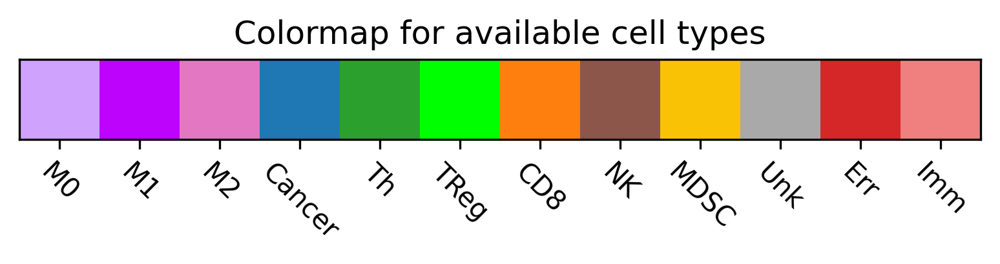

In [3]:
# Create colormaps used to plot
import matplotlib.colors as mcolors
paired = plt.cm.Paired.colors
paired_to9 = mcolors.ListedColormap(paired[:9])
paired_to11 = mcolors.ListedColormap(paired[:11])

colormap = {
    1 : 0, # M1 macrophage
    2 : 1, # M2 macrophage
    3 : 2, # cancer
    4 : 3, # Th
    5 : 4, # Treg
    6 : 5, # CD8
    8 : 6, # NK
    10 : 7, # MDSC
    -10 : 8 # errortype or unknown
} 

cell_colors = [
    'xkcd:lilac', # M0
    'xkcd:bright purple', # M1
    'tab:pink', # M2
    'tab:blue', # cancer
    'tab:green', # CD4 T helper
    'lime', # CD4 TReg
    'tab:orange', # CD8
    'tab:brown', # NK cell
    'xkcd:goldenrod', # MDSC
    'darkgray', # Unknown cell
    'tab:red', # Error-type
    'lightcoral' # Generalized immune
]

cell_cmap = mcolors.ListedColormap(cell_colors)
fig, ax = plt.subplots()
fig.set_dpi(300)
ax.imshow([np.arange(len(cell_colors))], cmap=cell_cmap)
ax.set_xticks(np.arange(len(cell_colors)), ["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unk", "Err", "Imm"], rotation=-45)
ax.set(title="Colormap for available cell types")
ax.yaxis.set_visible(False)

name_to_type = {
    "M1" : 0, # M1 macrophage
    "M2" : 1, # M2 macrophage
    "cancer" : 2, # cancer
    "CD4" : 3, # Th
    "Treg" : 4, # Treg
    "treg" : 4, # also Treg
    "TReg" : 4, # Treg
    "CD8" : 5, # CD8
    "NK" : 6, # NK
    "MDSC" : 7, # MDSC
    "unknown" : 8, # errortype or unknown
    "error_type" : 9, # errortype or unknown
    "immune" : 10 # errortype or unknown
}

['error_type', 'unknown', 'CD8', 'CD4', 'MDSC', 'M1', 'M2', 'NK',
       'cancer', 'treg', 'Treg', 'immune']

apply_cmap = lambda x : colormap[x]
apply_type = lambda x : name_to_type[x]

plt.style.use('dark_background')

In [ ]:
# Peek at the treatment data
phenos_space = ["Phenotype CD206", "Phenotype CD3", "Phenotype CD8", "Phenotype Foxp3", "Phenotype GR-1", "Phenotype HER2", "Phenotype MHCII", "Phenotype NCR1"]
tx_cells = pd.read_table("treatment_consolidated_data.txt", header=0, chunksize = 100000) # Need to load in chunks

i = 0
pivot_tables = []
cont = True
while cont:
    print(f"This is chunk {i}.")
    try:
        cells = next(tx_cells)
        cells["celltype"] = cells[phenos_space].apply(identify_celltype, args=[id_dict, True], axis=1) # Get celltype
        pt = pd.pivot_table(cells, values="Cell ID", columns="celltype", aggfunc="count")
        pivot_tables.append(pt)
        print(pt)
        i += 1
        print("\n")
    except StopIteration:
        cont = False

summary_df = pivot_tables[0]
for i in range(len(pivot_tables) - 1):
    summary_df.loc[i+1] = pivot_tables[i+1].loc["Cell ID"]
summary_df.sum() / summary_df.sum().sum()

print(np.unique(np.array(missing_combos)))

In [41]:
missing_strings = [np.binary_repr(a, width=8)[::-1] for a in np.unique(missing_combos)]
missing_phenos = []
for string in missing_strings:
    rewrite = ""
    for i in range(8):
        rewrite += markers[i]
        if string[i] == "1":
            rewrite += "+ "
        else:
            rewrite += "- "
    missing_phenos.append(rewrite)

In [4]:
# Analyze all at once
all_cells = pd.read_csv("WholeTissueConsolidated_data.csv", header=0)
cell_types = ["M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"] # No M0
all_cells["UID"]= all_cells.apply(assemble_UID, axis=1) # Create unique ID per cell

# Discard all glass "cells"
all_cells = all_cells[all_cells["TissueCategory"] != "Glass"]
all_cells.drop(toss, axis=1, inplace=True) # Drop info not used to ID cells or celltype
all_cells["celltype"] = all_cells[phenos].apply(identify_celltype, args=[id_dict], axis=1) # Get celltype
all_cells.drop(phenos, axis=1, inplace=True) # Drop pheno from df
all_cells["celltype"] = all_cells["celltype"].replace({"Treg":"TReg", "treg":"Treg"}) # Fix Treg / treg / TReg labeling

In [7]:
# Export non-normalized statistics for each marker
for cell_type in cell_types:
    subset = all_cells[all_cells["celltype"] == cell_type]
    subset = subset.drop(["CellXPosition", "CellYPosition"], axis=1)
    stats = subset.describe()
    stats.to_csv(f"metastases_info/statistics/{cell_type}.csv")

In [5]:
# Normalize markers using StandardScaler
# You do not need to normalize the cells when doing RF
all_cells = all_cells[all_cells["celltype"] != "error_type"] # Get rid of error cells pre-scaling
scaler = sklearn.preprocessing.StandardScaler()
all_cells_znorm = scaler.fit_transform(all_cells.drop(["UID", "CellXPosition", "CellYPosition", "celltype"], axis=1))

# Annotate; use to_list because StandardScaler overwrites the pandas indices
all_cells_znorm = pd.DataFrame(all_cells_znorm, columns = all_cells.drop(["UID", "CellXPosition", "CellYPosition", "celltype"], axis=1).keys())
all_cells_znorm["UID"] = all_cells["UID"].to_list()
all_cells_znorm["celltype"] = all_cells["celltype"].to_list()

In [ ]:
# We will now plot the distributions of each marker for each cell type
import seaborn as sns
plt.style.use('default')

num_figs = int(220/5 - 1)
for k in range(num_figs):
    a = k*5
    fig, ax = plt.subplots(10, 5, sharex=True, figsize=(15, 5), dpi=300)
    print(f"Beginning plot {k + 1} of {num_figs + 1}")
    for j in range(5):
        feature = all_cells_znorm.keys()[a + j]
        for i in range(10):
            celltype = cell_types[i]
            color = cell_cmap.colors[i+1]
            if i == 9:
                celltype = cell_types[i+1]
                color = cell_cmap.colors[i+2]
            this_ax = ax[i, j]
            sns.kdeplot(all_cells_znorm[all_cells_znorm["celltype"] == celltype], x=feature, ax = this_ax, color=color, fill=True)
            this_ax.set(xlim=(-5, 5), ylabel="", xlabel="")
            this_ax.set_yticks([]) # No y ticks
            this_ax.spines['top'].set_visible(False)
            this_ax.spines['right'].set_visible(False) # No y ticks
        ax[0, j].set(title=feature)
        ax[-1, j].set(xlabel="Z-score")
    plt.subplots_adjust(wspace=0, hspace=1)
    fig.savefig(f"metastases_info/statistics/images/{feature}.png", dpi=300)
    fig.close()

In [8]:
from sklearn.cluster import MiniBatchKMeans, KMeans, MeanShift, estimate_bandwidth
import scanpy as sc
import scanpy.external as sce
import umap

# Remove features w/ NaN
nans = all_cells_znorm.drop(["UID", "celltype"], axis=1).isnull().sum()
nankeys = []
for key in nans.keys():
    if nans[key].sum() != 0:
        nankeys.append(key)

# These are the geometric features; no cytoplasm features
geoms_keep = ['NucleusAreasquareMicrons', 'NucleusCompactness', 'NucleusMinorAxis', 'NucleusMajorAxis', 'NucleusAxisRatio',
              'MembraneAreasquareMicrons', 'MembraneCompactness', 'MembraneMinorAxis', 'MembraneMajorAxis', 'MembraneAxisRatio',
              'EntireCellAreasquareMicrons', 'EntireCellCompactness','EntireCellMinorAxis', 'EntireCellMajorAxis', 'EntireCellAxisRatio']

cells_to_cluster = all_cells_znorm.drop(["UID", "celltype"], axis=1)
cells_to_cluster = cells_to_cluster.drop(nankeys, axis=1)

# Run this line to extract geometric features ONLY
cells_to_cluster = cells_to_cluster[geoms_keep]

adata = sc.AnnData(cells_to_cluster.reset_index(drop=True)) # AnnData for Leiden prior to adding obs back

# Perform UMAP
# umap = umap.UMAP(n_components=2, verbose=True)
# umap_coords = umap.fit_transform(cells_to_cluster)
# np.savetxt("geom_umap.csv", umap_coords, delimiter=",")

# First method: k-means clusters w/ a higher number of clusters than we expect.
# We have 8 cell types (M1, M2, Cancer, Th, TReg, CD8, NK, MDSC), so should use x2-x3 clusters
# Then we can merge the clusters using hierarchical clusters
kmeans = KMeans(n_clusters = 24, n_init="auto", verbose = False)
cells_to_cluster["k_means_cluster"] = kmeans.fit_predict(cells_to_cluster)
np.savetxt("geom_kmeans24.csv", cells_to_cluster["k_means_cluster"].to_numpy(), delimiter=",")

# Second method: mean-shift (similar to X-shift but a bit simpler)
bw = estimate_bandwidth(cells_to_cluster, quantile=0.2, n_samples=5000)
meanshift = MeanShift(bandwidth=bw, bin_seeding=True)
cells_to_cluster["ms_cluster"] = meanshift.fit_predict(cells_to_cluster)
np.savetxt("geom_meanshift.csv", cells_to_cluster["ms_cluster"].to_numpy(), delimiter=",")

# Load pre-computed clusters and coordinates
kmeans_clusters = np.loadtxt("geom_kmeans24.csv", delimiter=",")
ms_clusters = np.loadtxt("geom_meanshift.csv", delimiter=",")
cells_to_cluster["km_cluster"] = kmeans_clusters
cells_to_cluster["ms_cluster"] = ms_clusters
umap_coords = np.loadtxt("umap.csv", delimiter=",")
cells_to_cluster["UMAP-1"] = umap_coords[:, 0]
cells_to_cluster["UMAP-2"] = umap_coords[:, 1]

# Get colors for plotting & restore cell types and UID
cells_to_cluster["UID"] = all_cells_znorm["UID"].to_list()
cells_to_cluster["celltype"] = all_cells_znorm["celltype"].to_list()
cells_to_cluster["color"] = cells_to_cluster["celltype"].apply(apply_type)

adata.obs = cells_to_cluster[["UMAP-1", "UMAP-2", "km_cluster", "ms_cluster", "color"]] # Keep obs in case of sampling

# Third method: leiden clustering
nn = 20 # Tune this parameter
res = 1 # Tune this parameter
sc.settings.verbosity = 3 # Verbosity setting just to see how things are going
adata_sample = sc.pp.sample(adata, fraction=0.15, copy=True) # Test clustering parameters on a subsample of ~180000 cells
sc.tl.pca(adata_sample) # We run PCA in order to do the harmony integration step
# Doing the harmony integration requires us to separate out the different experiments; will do this later...
# sce.pp.harmony_integrate(adata=adata_sample, key='array', max_iter_harmony = 30) # Improves results w/ multiple samples
sc.pp.neighbors(adata_sample, n_neighbors=nn, metric='euclidean', random_state=0)
sc.tl.leiden(adata_sample, resolution=res, key_added="leiden")

/apps/conda/envs/ood-jupyterlab-4.4/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Initialization complete
Iteration 0, inertia 4062344.5849808636.
Iteration 1, inertia 3339999.9638660797.
Iteration 2, inertia 3252586.799140899.
Iteration 3, inertia 3205696.249516932.
Iteration 4, inertia 3176350.2451591445.
Iteration 5, inertia 3153104.568978566.
Iteration 6, inertia 3137412.036423717.
Iteration 7, inertia 3125302.571004179.
Iteration 8, inertia 3116240.8113423795.
Iteration 9, inertia 3110000.9977037935.
Iteration 10, inertia 3105298.2635007114.
Iteration 11, inertia 3101316.8494482.
Iteration 12, inertia 3097604.809164826.
Iteration 13, inertia 3093997.9411038384.
Iteration 14, inertia 3090488.0174466884.
Iteration 15, inertia 3087123.20529495.
Iteration 16, inertia 3083939.27846828.
Iteration 17, inertia 3081095.686189391.
Iteration 18, inertia 3078417.148301875.
Iteration 19, inertia 3075917.512061715.
Iteration 20, inertia 3073684.3370043873.
Iteration 21, inertia 3071718.63489176.
Iteration 22, inertia 3070033.9287740076.
Iteration 23, inertia 3068558.85150339

/apps/conda/envs/ood-jupyterlab-4.4/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=14
    finished (0:00:00)
computing neighbors
    using data matrix X directly
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:42)
running Leiden clustering


/tmp/SLURM_1847548/ipykernel_2721643/4160646641.py:69: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_sample, resolution=res, key_added="leiden")


    finished: found 63 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:05:27)


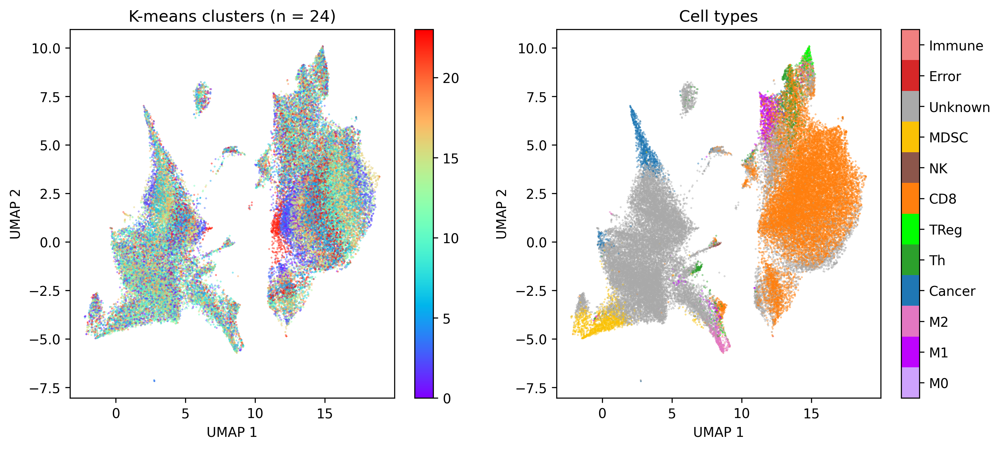

In [9]:
# Use UMAP coordinates to plot clusters
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Get mean-shift data
# labels = meanshift.labels_
# labels_unique = np.unique(labels)
# n_ms_clusters_ = len(labels_unique)

cells_to_plot = cells_to_cluster.sample(50000)  

c1 = ax1.scatter(cells_to_plot["UMAP-1"], cells_to_plot["UMAP-2"], c=cells_to_plot["km_cluster"], cmap="rainbow", s=.05)
ax1.set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"K-means clusters (n = {24})")
cbar1 = plt.colorbar(c1)

c2 = ax2.scatter(cells_to_plot["UMAP-1"], cells_to_plot["UMAP-2"], c=cells_to_plot["color"], cmap=cell_cmap, clim=[-1, 11], s=.05)

ax2.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Cell types")
cbar2 = plt.colorbar(c2)
cbar2.set_ticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
cbar2.set_ticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])

#fig.savefig(f"km_{24}cluster_clusterplot.png", dpi=300)
fig.savefig(f"geom_km_{24}cluster_clusterplot.png", dpi=300)

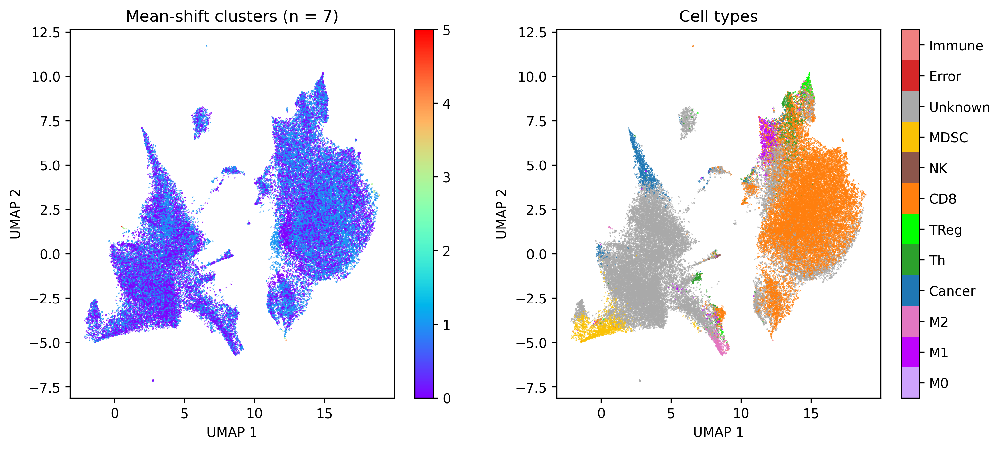

In [22]:
# Use UMAP coordinates to plot clusters
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

# Get mean-shift data
labels = meanshift.labels_
labels_unique = np.unique(labels)
n_ms_clusters_ = len(labels_unique)

cells_to_plot = cells_to_cluster.sample(50000)  

c1 = ax1.scatter(cells_to_plot["UMAP-1"], cells_to_plot["UMAP-2"], c=cells_to_plot["ms_cluster"], cmap="rainbow", s=.05)
ax1.set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"Mean-shift clusters (n = {n_ms_clusters_})")
cbar1 = plt.colorbar(c1)

c2 = ax2.scatter(cells_to_plot["UMAP-1"], cells_to_plot["UMAP-2"], c=cells_to_plot["color"], cmap=cell_cmap, clim=[-1, 11], s=.05)

ax2.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Cell types")
cbar2 = plt.colorbar(c2)
cbar2.set_ticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
cbar2.set_ticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])

#fig.savefig(f"km_{24}cluster_clusterplot.png", dpi=300)
fig.savefig(f"geom_ms_{n_ms_clusters_}cluster_clusterplot.png", dpi=300)

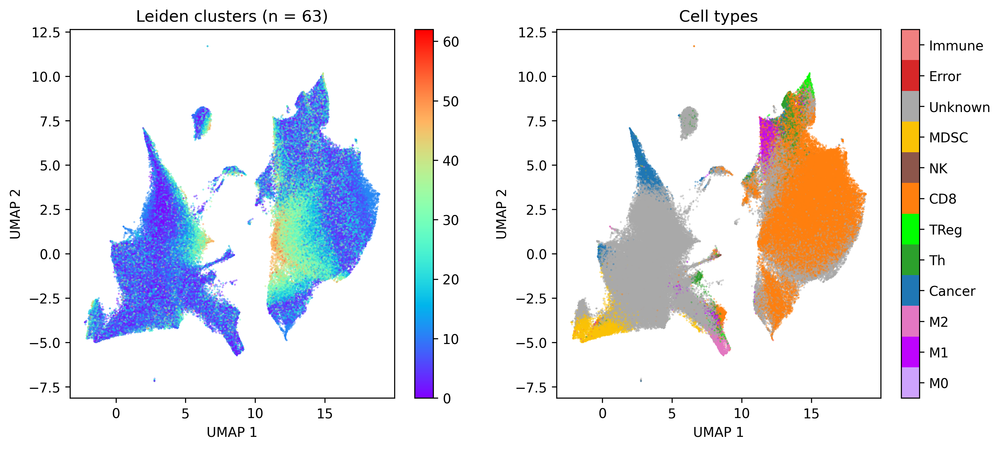

In [10]:
# Plot using UMAP & the Leiden clustering
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=300)
n_clusters = len(adata_sample.obs.leiden.unique())

c1 = ax1.scatter(adata_sample.obs["UMAP-1"], adata_sample.obs["UMAP-2"], c=adata_sample.obs["leiden"].astype(int), cmap="rainbow", s=.05)
ax1.set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"Leiden clusters (n = {n_clusters})")
cbar1 = plt.colorbar(c1)

c2 = ax2.scatter(adata_sample.obs["UMAP-1"], adata_sample.obs["UMAP-2"], c=adata_sample.obs["color"].to_list(), cmap=cell_cmap, clim=[-1, 11], s=.05)

ax2.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Cell types")
cbar2 = plt.colorbar(c2)
cbar2.set_ticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
cbar2.set_ticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])

fig.savefig(f"ld_{n_clusters}cluster_clusterplot.png", dpi=300)

<Axes: xlabel='km_cluster', ylabel='celltype'>

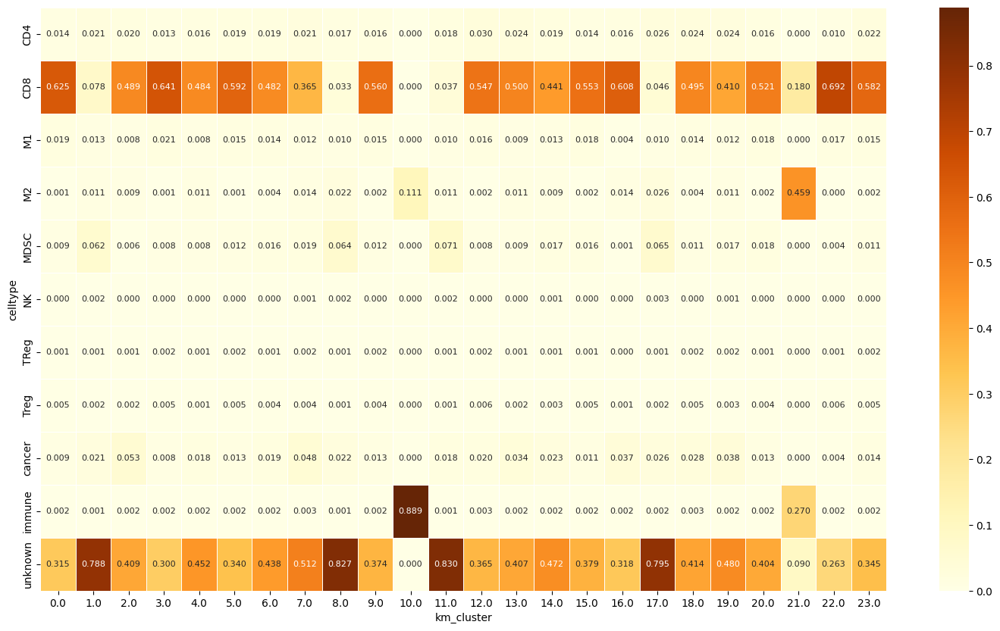

In [11]:
# Now we plot the prevalance of each cell type by cluster
import seaborn as sns
plt.style.use("default")

fig, ax = plt.subplots(1, 1, figsize=(18, 10), dpi=100)
cluster_composition = pd.pivot_table(cells_to_cluster, values="UID", index="km_cluster", columns="celltype", aggfunc="count") # pivot data on single value
cluster_composition = cluster_composition.div(cluster_composition.sum(axis=1), axis=0)
sns.heatmap(cluster_composition.transpose().fillna(0), ax=ax, cmap=sns.color_palette("YlOrBr", as_cmap=True), linewidth=.5,
           annot=True, annot_kws={"size": 8}, fmt=".3f")

/tmp/SLURM_1847548/ipykernel_2721643/4224848601.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp_table["counter"] = np.ones(len(temp_table))
/tmp/SLURM_1847548/ipykernel_2721643/4224848601.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  cluster_composition = pd.pivot_table(temp_table, values="counter", index="leiden", columns="color", aggfunc="count") # pivot data on single value


<Axes: xlabel='leiden', ylabel='color'>

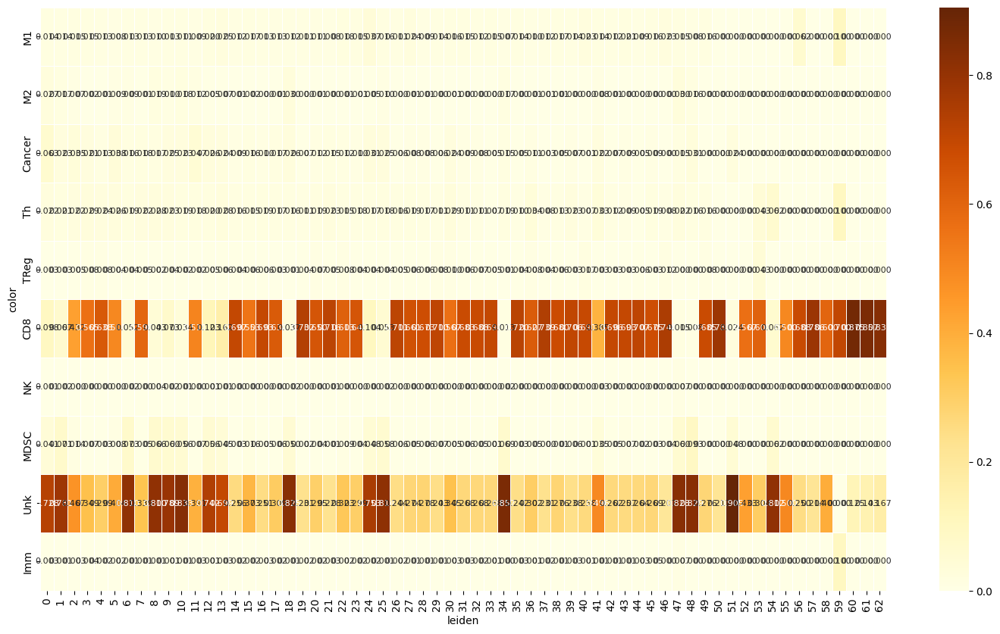

In [12]:
# Now we plot the prevalance of each cell type by cluster using AnnData object
import seaborn as sns
plt.style.use("default")

temp_table = adata_sample.obs[["leiden", "color"]]
temp_table["counter"] = np.ones(len(temp_table))

fig, ax = plt.subplots(1, 1, figsize=(18, 10), dpi=100)
cluster_composition = pd.pivot_table(temp_table, values="counter", index="leiden", columns="color", aggfunc="count") # pivot data on single value
cluster_composition = cluster_composition.div(cluster_composition.sum(axis=1), axis=0)
sns.heatmap(cluster_composition.transpose().fillna(0), ax=ax, cmap=sns.color_palette("YlOrBr", as_cmap=True), linewidth=.5,
           annot=True, annot_kws={"size": 8}, fmt=".3f", yticklabels=["M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unk", "Imm"])

In [8]:
# Try out a RandomForest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

all_cells["celltype"] = all_cells["celltype"].replace({"Treg":"TReg", "treg":"Treg"}) # Fix Treg / treg / TReg labeling
all_cells = all_cells[all_cells["celltype"] != "error_type"] # Remove error-type cells
umap_coords = np.loadtxt("umap.csv", delimiter=",")
all_cells["UMAP-1"] = umap_coords[:, 0]
all_cells["UMAP-2"] = umap_coords[:, 1]

labeled_data = all_cells[all_cells["celltype"] != "unknown"] # Remove unknown cells
labeled_data = labeled_data[labeled_data["celltype"] != "immune"] # Remove immune cells

annots = labeled_data[["CellXPosition", "CellYPosition", "UID", "celltype", "UMAP-1", "UMAP-2"]]
labeled_data.drop(["CellXPosition", "CellYPosition", "UID", "celltype", "UMAP-1", "UMAP-2"], axis=1, inplace=True)
# labeled_data = labeled_data[geoms_keep]

X_train, X_test, y_train, y_test = train_test_split(labeled_data, annots["celltype"], random_state=0) # Can do k-fold cross-validation later for more robust
rf = RandomForestClassifier(n_estimators = 200, criterion='gini', n_jobs=-1, random_state=0, 
                            verbose=1, class_weight="balanced") # Default values & use all available threads; verbosity to track progress; train on balanced dataset

rf.fit(X_train, y_train)
rf.score(X_test, y_test)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:   11.6s
[Parallel(n_jobs=-1)]: Done 152 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  1.7min finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.1s
[Parallel(n_jobs=24)]: Done 152 tasks      | elapsed:    0.4s
[Parallel(n_jobs=24)]: Done 200 out of 200 | elapsed:    0.5s finished


0.9832290461152194

[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.1s
[Parallel(n_jobs=24)]: Done 152 tasks      | elapsed:    0.4s
[Parallel(n_jobs=24)]: Done 200 out of 200 | elapsed:    0.5s finished


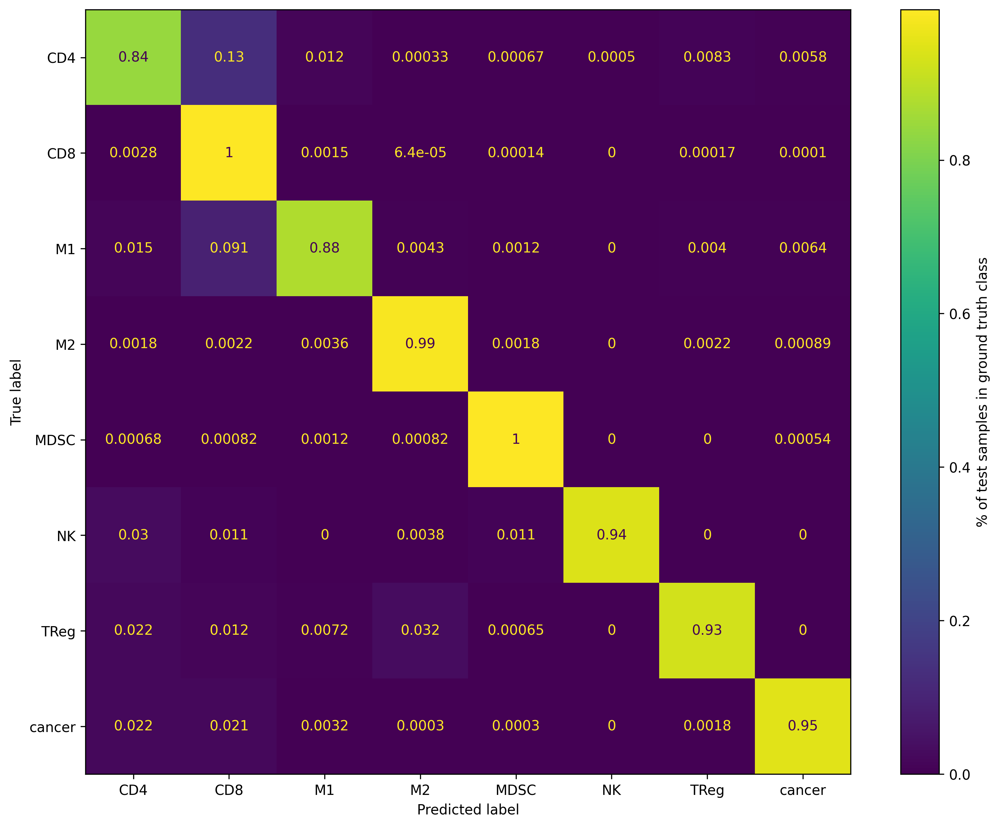

In [9]:
plt.style.use('default')
fig, ax = plt.subplots(1, 1, figsize=(13, 10), dpi=300)
cm = sklearn.metrics.ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, display_labels=rf.classes_, ax=ax, normalize="true", colorbar=False)
cbar = fig.colorbar(cm.im_, ax = ax)
cbar.set_label("% of test samples in ground truth class")

In [14]:
#import joblib
#joblib.dump(rf, "all_nontx_data_rf.joblib")

[Text(0, 0.5, 'Gini Importance'), Text(0.5, 1.0, 'Top 30 features')]

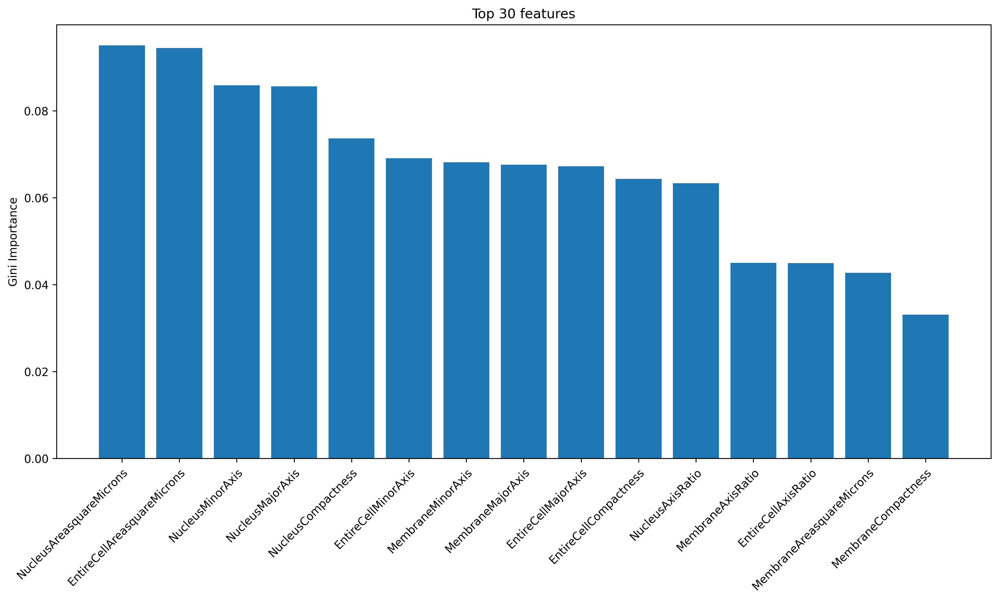

In [19]:
features = pd.DataFrame([rf.feature_importances_, rf.feature_names_in_])
features = features.transpose()
features = features.rename(columns={0: "Importance", 1: "Name"})
features.sort_values("Importance", axis=0, ascending=False, inplace=True)

fig, ax = plt.subplots(1, 1, figsize=(15, 7), dpi=300)
ax.bar(np.arange(15), features["Importance"][:15])
ax.set_xticks(np.arange(15), features["Name"][:15], rotation=45, rotation_mode='anchor', ha='right')
ax.set(ylabel="Gini Importance", title="Top 30 features")

[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.1s
[Parallel(n_jobs=24)]: Done 152 tasks      | elapsed:    0.5s
[Parallel(n_jobs=24)]: Done 200 out of 200 | elapsed:    0.6s finished


RF balanced accuracy score on the test set is 0.9400128799650214.


[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.1s
[Parallel(n_jobs=24)]: Done 152 tasks      | elapsed:    1.4s
[Parallel(n_jobs=24)]: Done 200 out of 200 | elapsed:    1.7s finished
/tmp/SLURM_1861998/ipykernel_2789612/3085303381.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unknowns["rf_pred_label"] = unknown_pred
/tmp/SLURM_1861998/ipykernel_2789612/3085303381.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a

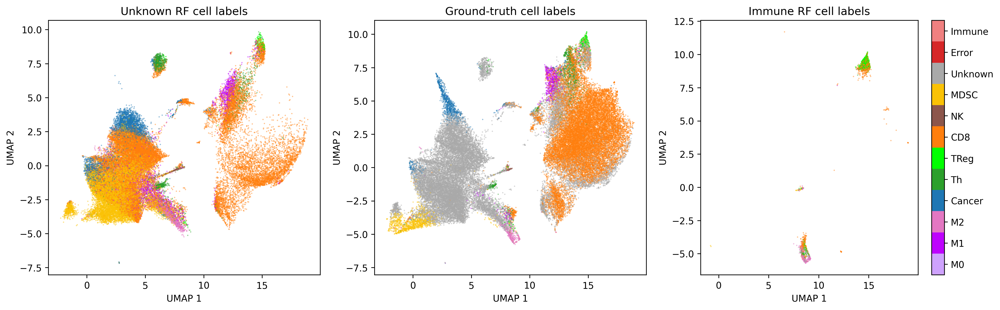

In [16]:
# Determine balanced accuracy
ypred = rf.predict(X_test)
balanced_score = sklearn.metrics.balanced_accuracy_score(y_test, ypred)
print(f"RF balanced accuracy score on the test set is {balanced_score}.")

fnames = rf.feature_names_in_

# Predict probabilitys of unknown data
unknowns = all_cells[all_cells["celltype"] == "unknown"]
immunes = all_cells[all_cells["celltype"] == "immune"]
unknown_pred = rf.predict(unknowns[fnames])
unknowns["rf_pred_label"] = unknown_pred
unknowns["rf_pred_class"] = unknowns["rf_pred_label"].apply(apply_type)
immune_pred = rf.predict(immunes[fnames])
immunes["rf_pred_label"] = immune_pred
immunes["rf_pred_class"] = immunes["rf_pred_label"].apply(apply_type)

# Plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5), dpi=300)
cells_to_plot = all_cells.sample(50000) # Subsample of the base to plot
cells_to_plot["color"] = cells_to_plot["celltype"].apply(apply_type)
unk_to_plot = unknowns.sample(50000) # Subsample of unknowns to plot

c1 = ax1.scatter(unk_to_plot["UMAP-1"], unk_to_plot["UMAP-2"], c=unk_to_plot["rf_pred_class"], cmap=cell_cmap, clim=[-1, 11], s=.05)
ax1.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Unknown RF cell labels")

c2 = ax2.scatter(cells_to_plot["UMAP-1"], cells_to_plot["UMAP-2"], c=cells_to_plot["color"], cmap=cell_cmap, clim=[-1, 11], s=.05)
ax2.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Ground-truth cell labels")

c3 = ax3.scatter(immunes["UMAP-1"], immunes["UMAP-2"], c=immunes["rf_pred_class"], cmap=cell_cmap, clim=[-1, 11], s=.05)
ax3.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Immune RF cell labels")
cbar3 = plt.colorbar(c3)
cbar3.set_ticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
cbar3.set_ticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])

# fig.savefig(f"km_{24}cluster_clusterplot.png", dpi=300)

[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.1s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.9s finished
[Parallel(n_jobs=24)]: Using backend ThreadingBackend with 24 concurrent workers.
[Parallel(n_jobs=24)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=24)]: Done 100 out of 100 | elapsed:    0.0s finished


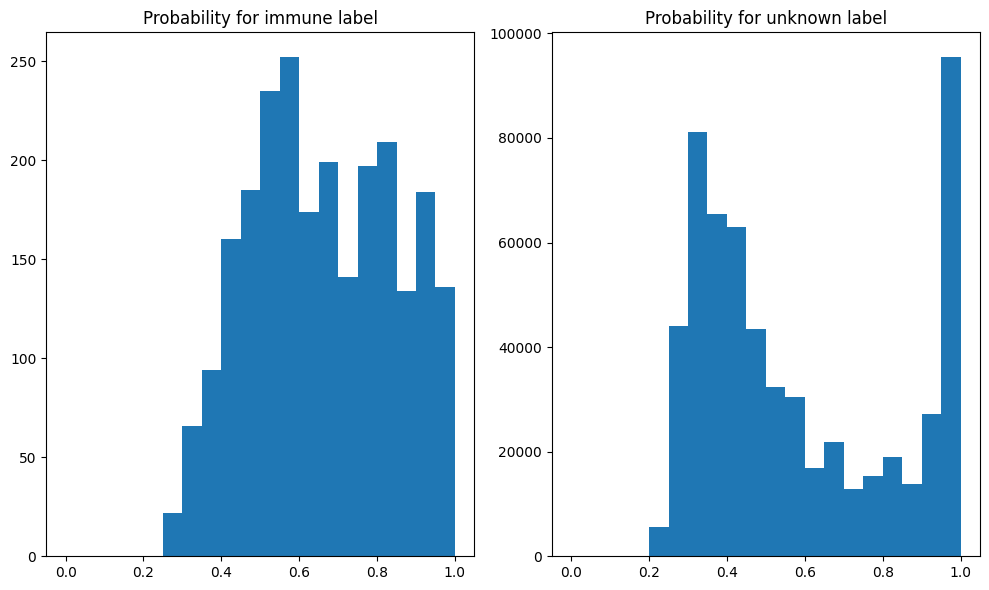

In [66]:
# Get prediction probabilities
unknown_probs = rf.predict_proba(unknowns.drop(["CellXPosition", "CellYPosition", "UID", "celltype", "UMAP-1", "UMAP-2", "rf_pred_class", "rf_pred_label"], axis=1, inplace=False))
immune_probs = rf.predict_proba(immunes.drop(["CellXPosition", "CellYPosition", "UID", "celltype", "UMAP-1", "UMAP-2", "rf_pred_class", "rf_pred_label"], axis=1, inplace=False))

# Extract maximum probability e.g. the probability of the class label
immune_class_prob = np.max(immune_probs, axis=1)
unknown_class_prob = np.max(unknown_probs, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), dpi=100)
ax1.hist(immune_class_prob, bins=20, range=(0, 1))
ax1.set(title="Probability for immune label")
ax2.hist(unknown_class_prob, bins=20, range=(0, 1))
ax2.set(title="Probability for unknown label")
plt.tight_layout()

In [30]:
# Export normalized statistics for each marker
for cell_type in cell_types:
    subset = all_cells_znorm[all_cells_znorm["celltype"] == cell_type]
    stats = subset.describe()
    stats.to_csv(f"metastases_info/statistics/{cell_type}_znorm.csv")

In [ ]:
# Analyze in chunks
num_chunks = 24
cell_types = ["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"]
tot_cells = 0

chunksize = 100000
all_cells = pd.read_csv("WholeTissueConsolidated_data.csv", header=0, chunksize=chunksize)

for i in range(num_chunks):

    # Get data
    try:
        sample = next(all_cells) # Gets the next block of cells
    except StopIteration:
        break

    # Read in data
    tot_cells += len(sample)
    sample["UID"] = sample.apply(assemble_UID, axis=1) # Creates a unique ID for all cells
    sample.drop(toss, axis=1, inplace=True) # Drop info not used to ID cells or celltype
    sample["celltype"] = sample[phenos].apply(identify_celltype, args=[id_dict], axis=1) # Get celltype
    sample.drop(phenos, axis=1, inplace=True) # Drop pheno from df
    sample["celltype"] = sample["celltype"].replace({"Treg":"TReg", "treg":"Treg"}) # Fix Treg / treg / TReg labeling
    print(f"Sample {i} ({len(sample)} cells) yields:")
    print(sample["celltype"].value_counts()) # Print info about # of cells we see in each sample
    print("\n")

    # Iterate over cell types & stream data to new files
    for cell_type in cell_types:
        output_path = f"metastases_info/{cell_type}.csv"
        subset = sample[sample["celltype"] == cell_type]
        subset.to_csv(output_path, mode='a', header = not os.path.exists(output_path))
        

In [ ]:
folder = "metastases_data"
vcs = []
names = []

for file in os.listdir(folder):

    # Data extraction
    df = pd.read_csv(f"metastases_data/{file}")
    df["celltype"] = df.apply(identify_celltype, args=[id_dict], axis=1)
    df["legend"] = df["cell_state"].apply(apply_cmap)
    df["reclass"] = df["celltype"].apply(apply_type)

    # Plotting
    fig, ax = plt.subplots()
    fig.set_size_inches(10, 7)
    fig.set_dpi(300)
    ax.set_aspect("equal")
    df.plot.scatter("shiftedData1", "shiftedData2", s=.5, c="reclass", cmap=cell_cmap, ax=ax, clim=[-1,11])
    
    cax = fig.get_axes()[1]
    cax.set_yticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
    cax.set_yticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])
    cax.set_ylabel("")

    # Get data for plotting compositions
    vcs.append(df["celltype"].value_counts())
    names.append(file)

    # Save figure
    save_path = f"metastases_info/full_tumors/images/{file[:-4]}.png"
    fig.savefig(save_path, dpi=300)

    # Close figure
    plt.close(fig)
    

In [33]:
# Turn all the countdata into a dataframe
countdata = pd.DataFrame(vcs)
countdata["id"] = [name[:-4] for name in names]
countdata.set_index("id", inplace=True)

# Fix issue w/ Treg and treg
countdata["TReg"] = countdata["Treg"] + countdata["treg"]
countdata.drop(["Treg", "treg"], axis=1, inplace=True)

# Get the total cell counts
countdata["tot"] = countdata.sum(axis=1)

In [16]:
# Get data from extracted metastases

from scipy.spatial import ConvexHull, convex_hull_plot_2d

vcs = []
shapes = []
density = []
names = []

for file in os.listdir("extracted_met_data"):

    # Get data
    path_to_file = f"extracted_met_data/{file}"
    for subfile in os.listdir(path_to_file):
        if subfile[-4:] == ".csv":
            csv = subfile
    df = pd.read_csv(path_to_file + "/" + csv)
    df["celltype"] = df.apply(identify_celltype, args=[id_dict], axis=1)
    df["color_label"] = df["celltype"].apply(apply_type)

    # Get data for plotting compositions
    vcs.append(df["celltype"].value_counts())
    names.append(file)

    points = df[["shiftedData1", "shiftedData2"]].to_numpy() # Gives cells as points
    hull = ConvexHull(points) # Create convex hull from points
    shapes.append([hull.area, hull.volume]) # Store the perimeter and area of the hull
    density.append(len(df)/hull.volume) # Rough calculation for cells per area

    # Plotting
    fig, ax = plt.subplots()
    fig.set_size_inches(10, 7)
    fig.set_dpi(300)
    ax.set_aspect("equal")
    for simplex in hull.simplices: # Do the hull first
        ax.plot(points[simplex, 0], points[simplex, 1], 'w--', alpha = 0.3)
    df.plot.scatter("shiftedData1", "shiftedData2", s=.5, c="color_label", cmap=cell_cmap, ax=ax, clim=[-1,11])
    ax.set(title=file[17:-10]) # Removes leading "121223 P9smP61-2" and tail "_extracted" from title

    # Colorbar settings
    cax = fig.get_axes()[1]
    cax.set_yticks([-0.5, .5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5])
    cax.set_yticklabels(["M0", "M1", "M2", "Cancer", "Th", "TReg", "CD8", "NK", "MDSC", "Unknown", "Error", "Immune"])
    cax.set_ylabel("")

    # Save figure
    save_path = f"metastases_info/extracted_tumors/images/{file}.png"
    fig.savefig(save_path, dpi=300)

    # Close figure
    plt.close(fig)

In [54]:
# Turn all the countdata into a dataframe
countdata = pd.DataFrame(vcs)
countdata["id"] = [name[17:-10] for name in names]
countdata.set_index("id", inplace=True)


# Fix issue w/ Treg and treg
countdata["TReg"] = countdata["Treg"] + countdata["treg"]
countdata.drop(["Treg", "treg"], axis=1, inplace=True)

# Get the total cell counts
countdata["tot"] = countdata.sum(axis=1)
countdata[["perimeter", "area"]] = shapes
countdata["cell_density"] = [100*den for den in density] # cells per 100 square microns

In [54]:
# I/O for countdata
# countdata.to_csv("metastases_info/extracted_tumors/compositions.csv") # save as a csv
countdata = pd.read_csv("metastases_info/extracted_tumors/compositions.csv") # read in the CSV
countdata.set_index("id", inplace=True)

In [55]:
# countdata.sort_values('tot', axis=0, ascending=False, inplace=True)
countdata

,CD8,unknown,error_type,CD4,cancer,MDSC,M2,M1,NK,immune,TReg,tot,perimeter,area,cell_density
id,,,,,,,,,,,,,,,
#24 NeuN NT2.5 LM 5 wks #5_met_1,214.0,13.0,6.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,234.0,333.730274,7607.285,3.075999
#31 NeuN NT2.5 LM 4 wks #4_met_10,1.0,8157.0,26.0,1.0,298.0,114.0,10.0,4.0,1.0,NaN,NaN,8612.0,2388.697349,423874.605,2.032913
#10 NT2.5 LM Lungs 22d-1_met_1,2.0,149.0,1.0,1.0,44.0,1.0,8.0,NaN,NaN,NaN,NaN,206.0,458.871349,9814.275,2.098983
#31 NeuN NT2.5 LM 4 wks #4_met_5,1.0,1027.0,11.0,4.0,1284.0,101.0,14.0,11.0,NaN,NaN,NaN,2453.0,1262.682439,118053.425,2.086344
#14 NT2.5 LM Lungs 22d-5_met_2,108978.0,10152.0,2681.0,2992.0,162.0,117.0,69.0,2211.0,4.0,423.0,1046.0,128835.0,13419.170295,8339834.420,1.544815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
#29 NeuN NT2.5 LM 4 wks #2_met_15,63.0,9316.0,130.0,59.0,1319.0,325.0,128.0,189.0,5.0,1.0,71.0,11606.0,3427.756039,874603.540,1.327001
#13 NT2.5 LM Lungs 22d-4_met_3,2438.0,1797.0,84.0,751.0,35.0,6.0,144.0,74.0,12.0,198.0,132.0,5671.0,1894.250584,270917.710,2.093256
#28 NeuN NT2.5 LM 4 wks #1_met_5,4.0,12882.0,186.0,3.0,2087.0,135.0,28.0,8.0,NaN,NaN,NaN,15333.0,3491.194070,869111.650,1.764445


In [56]:
percents = countdata.div(countdata["tot"], axis=0)
percents.drop(["perimeter", "area", "cell_density"], axis=1, inplace=True)
percents.fillna(0, inplace=True)
percents["ncells"] = countdata["tot"]
percents["M0"] = np.zeros(len(percents))

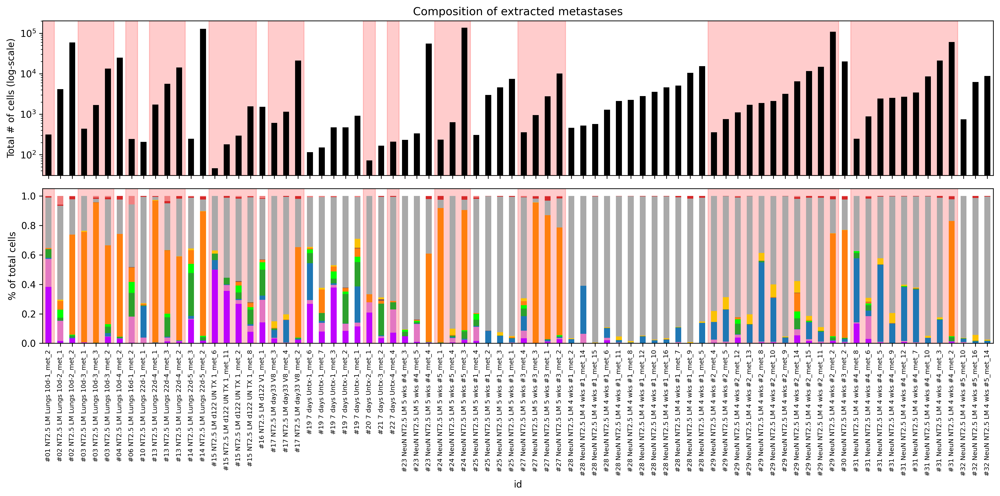

In [87]:
plt.style.use('default')

fig, ax = plt.subplots(2, 1, figsize=(15, 7.5), dpi=300, sharex=True)
percents["group"] = [idx[:3] for idx in percents.index]
percents = percents.sort_values(["group", "ncells"])
cell_makeup = percents[["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"]]

switch_at = [0, 1, 3, 6, 7, 8, 9, 12, 14, 18, 19, 22, 27, 28, 29, 30, 33, 36, 40, 44, 56, 67, 68, 77]
for i in range(len(switch_at)//2):
    a = switch_at[2*i]
    b = switch_at[2*i + 1]
    ax[0].axvspan(a-0.5, b-0.5, color='red', alpha=0.2)
    ax[1].axvspan(a-0.5, b-0.5, color='red', alpha=0.2)

    
cell_makeup.plot(kind='bar', stacked=True, ax=ax[1], color=cell_cmap.colors, legend=False, xticks=np.arange(len(percents))**2  )
percents["ncells"].plot(kind='bar', ax=ax[0], color="k")
ax[0].set_yscale('log')
ax[0].set(title="Composition of extracted metastases", ylabel="Total # of cells (log-scale)")
ax[1].set(ylabel="% of total cells")
ax[1].tick_params(axis='x', which='both', labelsize=7)

plt.tight_layout()
fig.savefig("metastases_info/extracted_tumors/compositions.png", dpi=300)

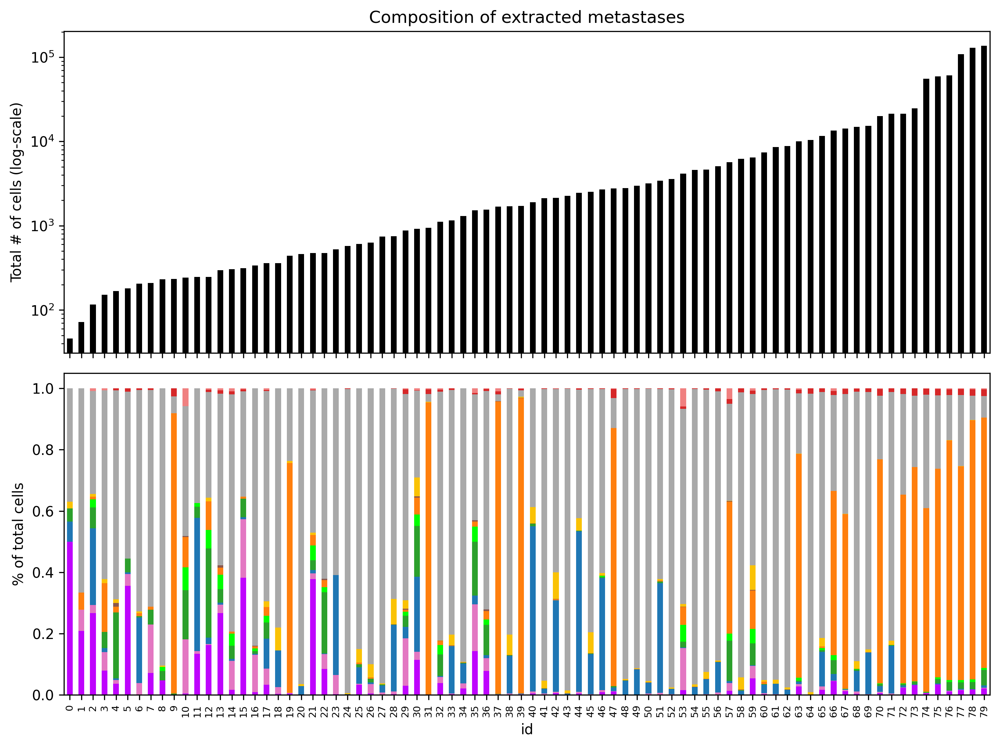

In [95]:
plt.style.use('default')

ig, ax = plt.subplots(2, 1, figsize=(10, 7.5), dpi=300, sharex=True)
percents = percents.sort_values("ncells")
cell_makeup = percents[["M0", "M1", "M2", "cancer", "CD4", "TReg", "CD8", "NK", "MDSC", "unknown", "error_type", "immune"]]
cell_makeup.plot(kind='bar', stacked=True, ax=ax[1], color=cell_cmap.colors, legend=False)
percents["ncells"].plot(kind='bar', ax=ax[0], color="k")
ax[0].set_yscale('log')
ax[0].set(title="Composition of extracted metastases", ylabel="Total # of cells (log-scale)")
ax[1].set(ylabel="% of total cells")
ax[1].tick_params(axis='x', which='both', labelsize=7)
ax[1].set_xticks(np.arange(80), labels=np.arange(80))

plt.tight_layout()